In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
from bioio import BioImage

data_path = Path("/media/pandora/Greger_group/Xinyao/PRRT Revision/PRRTm750 A1rb647 PSDck555 RIMgp488/261007 Repeat/Experiment-152.czi")

image = BioImage(data_path)
data = image.xarray_dask_data

In [5]:
import napari
v = napari.Viewer()
v.add_image(image.data, channel_axis=1)

[<Image layer 'Image' at 0x7fc2906b6510>,
 <Image layer 'Image [1]' at 0x7fc2901fe490>,
 <Image layer 'Image [2]' at 0x7fc2901fda90>,
 <Image layer 'Image [3]' at 0x7fc2901fec10>]

# 2. Drift correction

In [3]:
from prrt_clustering import correct_z_drift

shift, stabilized = correct_z_drift(data)

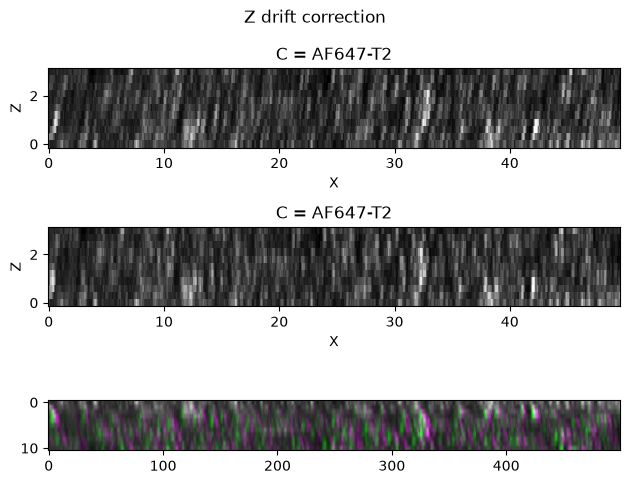

In [4]:
import numpy as np
import matplotlib.pyplot as plt
n = 500
a = data[0,1,:,:n,:n].max(axis=1)
b = stabilized[0,1,:,:n,:n].max(axis=1)
plt.subplot(311)
a.plot(add_colorbar=False,cmap='gray')
plt.subplot(312)
b.plot(add_colorbar=False,cmap='gray')
plt.subplot(313)
plt.imshow(np.stack([a,b,a],axis=2),aspect=4)
plt.suptitle('Z drift correction')
plt.tight_layout()

In [ ]:
# import napari
# v = napari.Viewer()
# v.add_image(image.data, channel_axis=1)
# v.add_image(stabilized.data[0,0,:,:100,:100], channel_axis=1)

## 2. Spot detection

In [ ]:
# from spotiflow.model import Spotiflow
# import matplotlib.pyplot as plt
# import numpy as np

# model = Spotiflow.from_pretrained("general")
# tmp = stabilized.data[0,2,:,:500,:500]
# points, details = model.predict(tmp)

# plt.imshow(np.sqrt(tmp),cmap='gray')
# plt.plot(points[:,1],points[:,0],'.',ms=20,mfc="none")

(<Figure size 2000x2000 with 1 Axes>, [<Axes: >])

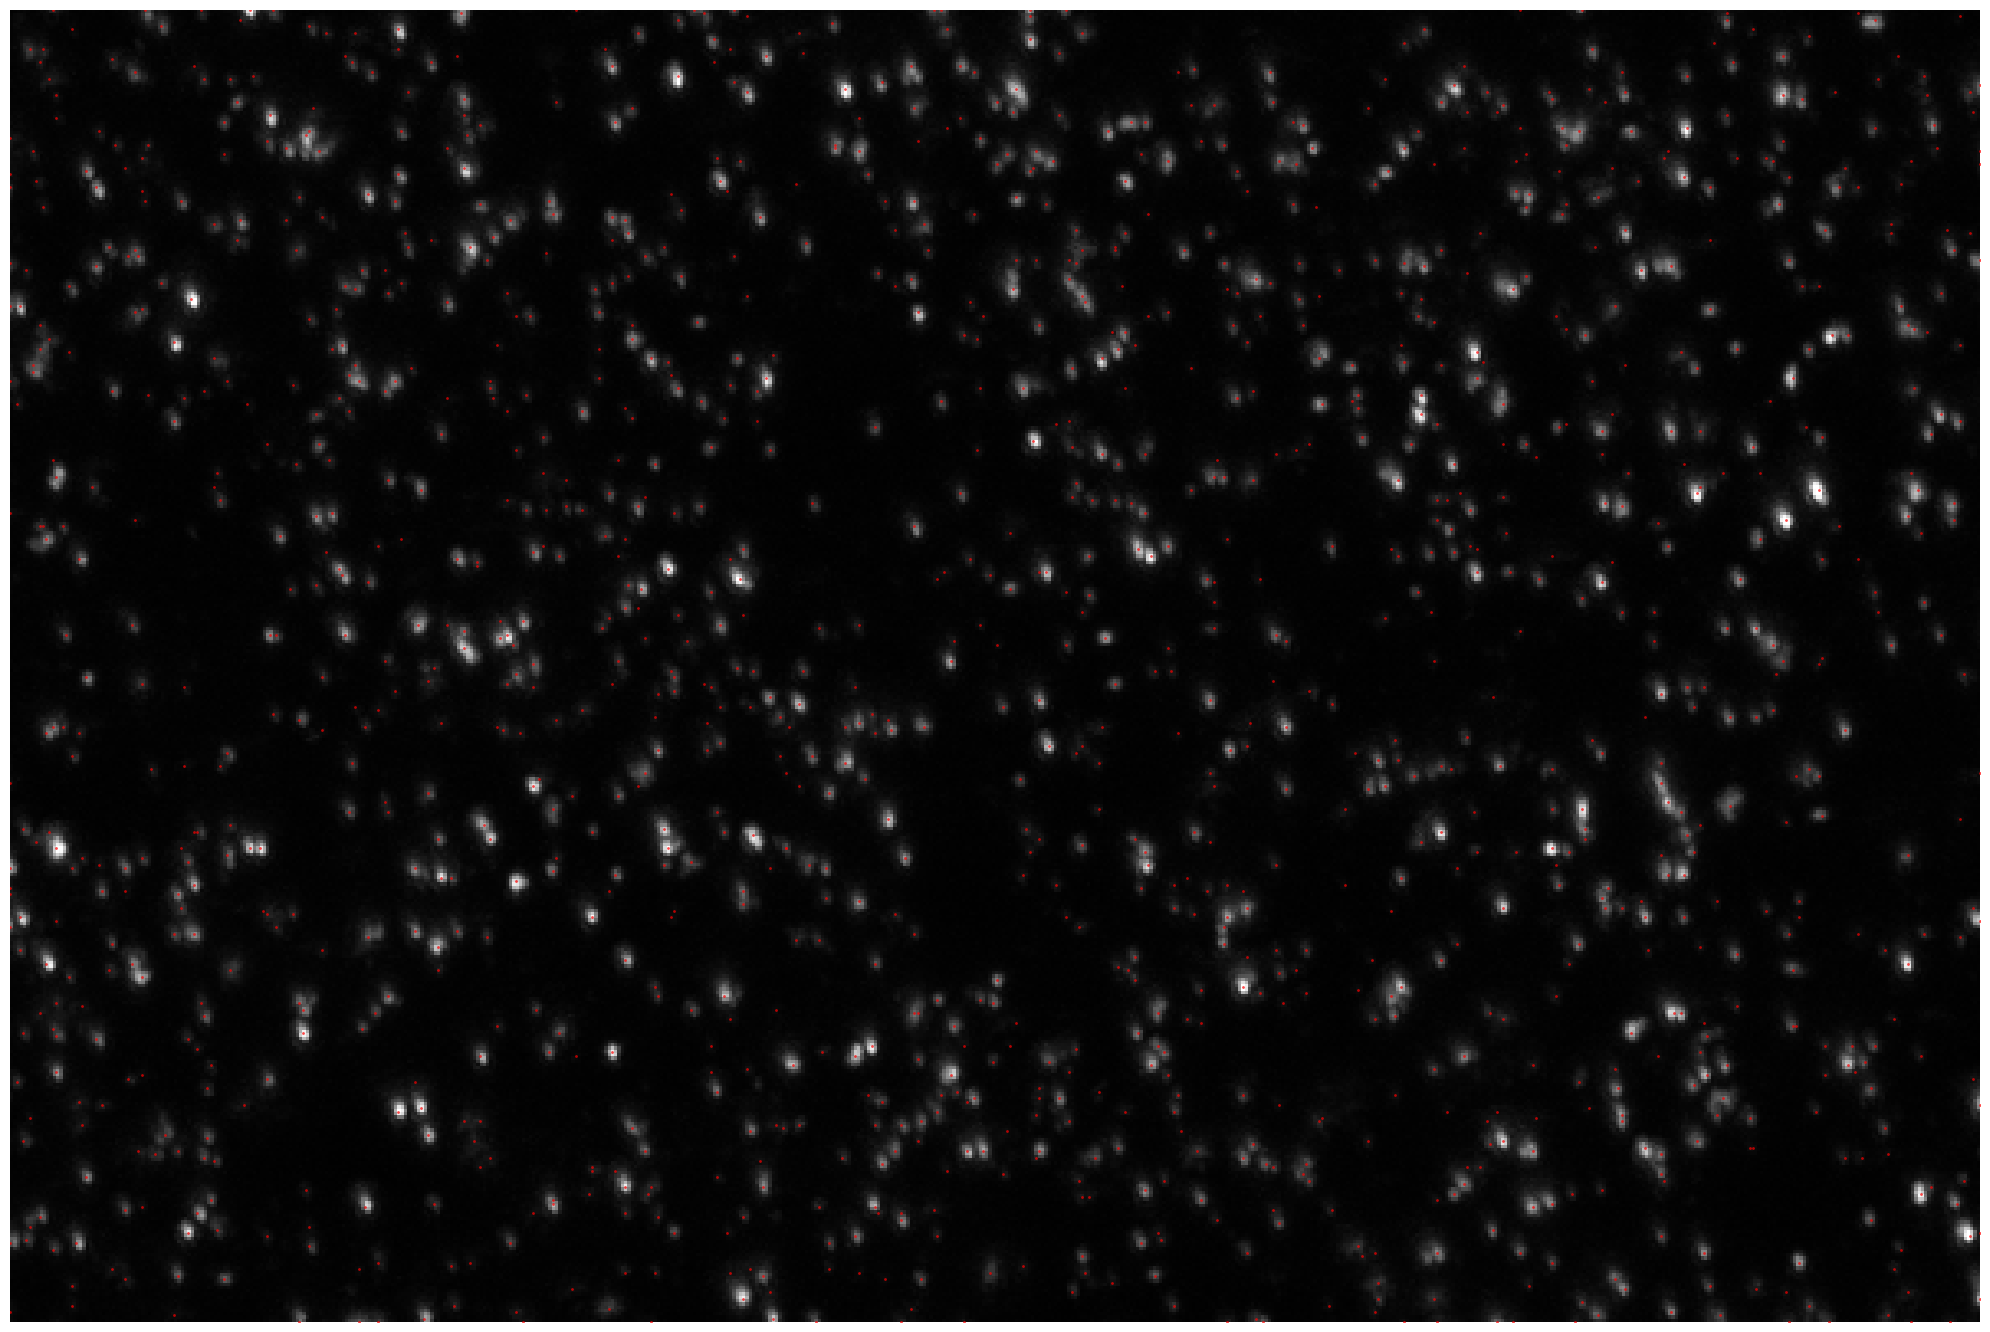

In [ ]:
from prrt_clustering import detect_puncta,plot_data,plot_points
import matplotlib.pyplot as plt
import numpy as np

tmp = stabilized[0,3,:,300:700,900:1500]

points = detect_puncta(tmp, scale_um=0.15, specificity=3, subpixel=False)
fig = plt.figure(figsize=(20,20))
fig, axes = plot_data(tmp,split=True,fig=fig)
plot_points(points, ms=2, split=True, axes=axes)


cc True


(<Figure size 2000x2000 with 4 Axes>,
 array([<Axes: >, <Axes: >, <Axes: >, <Axes: >], dtype=object))

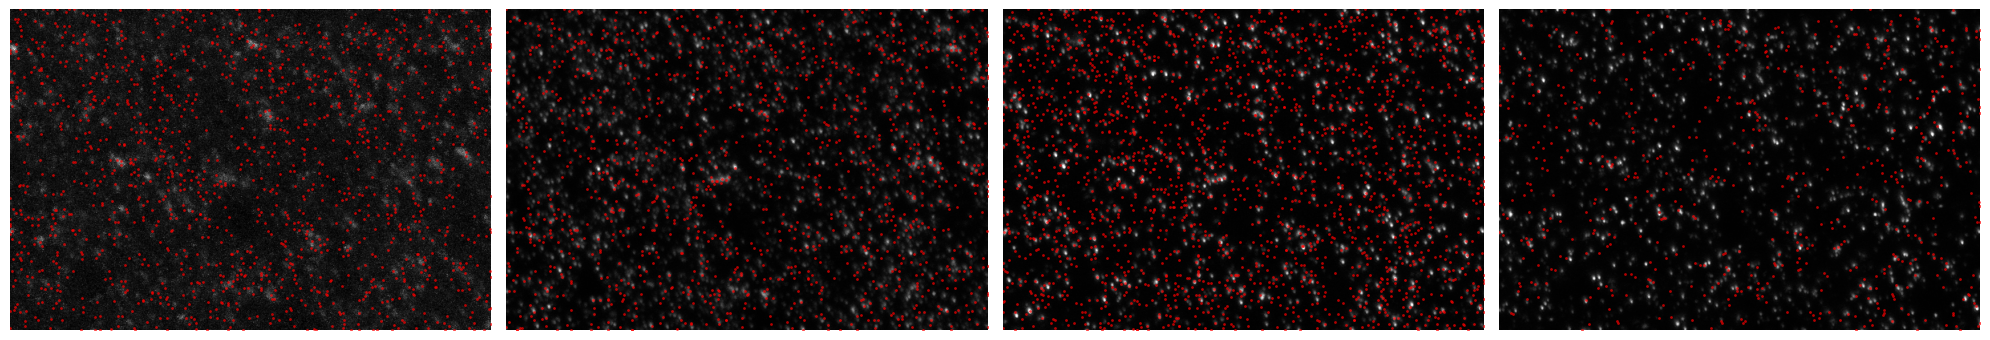

(<Figure size 640x480 with 1 Axes>, [<Axes: >, <Axes: >, <Axes: >, <Axes: >])

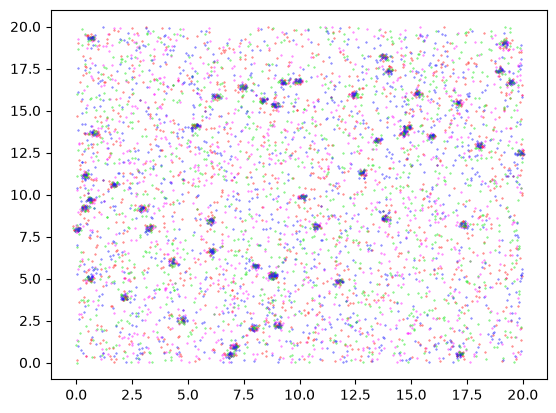

In [ ]:
import pandas as pd

D, H, W = 4, 20, 20
clst = np.random.uniform(low=[0, 0, 0, 0.5], high=[D, H, W, 1], size=(50, 4))
points = pd.concat(
    [
        pd.DataFrame(
            np.vstack(
                [
                    *[
                        np.random.normal(loc=x, scale=0.1, size=(10, 4))
                        for x in clst
                    ],
                    np.random.uniform(
                        low=[0, 0, 0, 0.5], high=[D, H, W, 1], size=(1000, 4)
                    ),
                ]
            ),
            columns=["Z", "Y", "X", "intensity"],
        ).assign(C=channel)
        for channel in "ABCD"
    ]
)


plot_points(points,ms=1)


In [72]:
from prrt_clustering import clean_points, create_synthetic_point_cloud

points = create_synthetic_point_cloud()
clean = clean_points(points)
plot_points(clean)

ImportError: cannot import name 'clean_points' from 'prrt_clustering' (/home/jeromeb/work/code/greger/xinyao/prrt_clustering/src/prrt_clustering/__init__.py)

In [44]:
tmp.interp(X=points.iloc[0]["X"],Y=points.iloc[0]["Y"],Z=points.iloc[0]["Z"]).sel(C=points.iloc[0]["C"]).values.item()

58.99999999996448

In [ ]:
import napari
v = napari.Viewer(ndisplay=3)
# v.add_image(image.data, channel_axis=1)
vx = np.array([(tmp[a][1].values - tmp[a][0].values) for a in ["Z", "Y", "X"]])
o = np.array([tmp[a][0].values for a in ["Z", "Y", "X"]])
print(o)
v.add_image(tmp,scale=vx,translate=o, channel_axis=0)
for c in points:
    v.add_points(c['coordinates'], size=0.5)

## 3. Clustering
Cluster points to identify potential synapses.

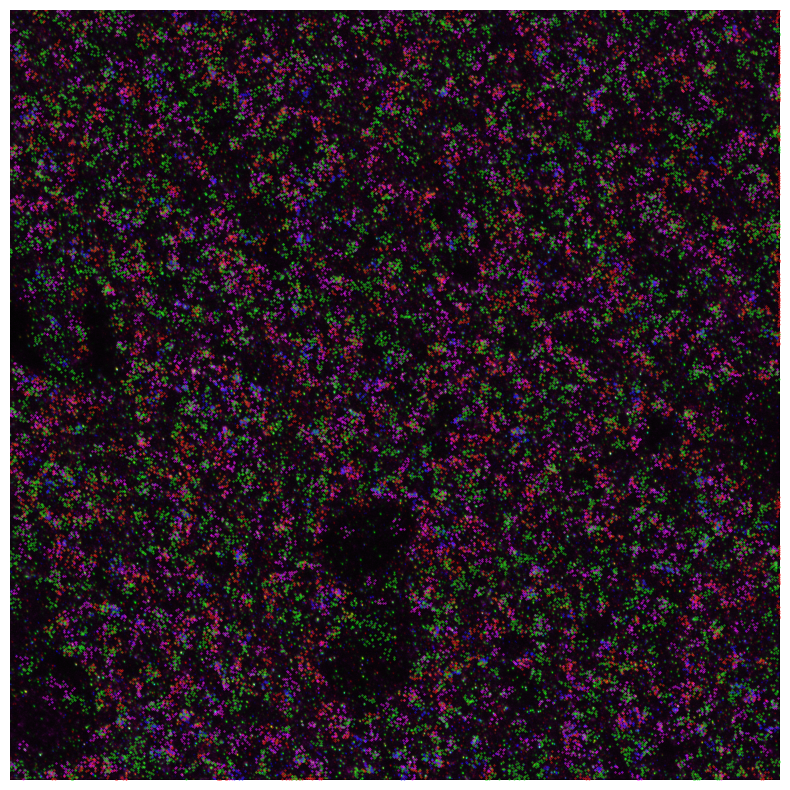

In [5]:
from prrt_clustering import cluster

clean = cluster(points, 2, 7)
plt.figure(figsize=(10,10))
plot_data(tmp)
plot_points(clean,ms=1)

In [22]:
points

,Z,Y,X,C,intensity
0,0.0,29.766020,98.823185,AF647-T2,1.0
1,0.0,29.766020,114.003855,AF647-T2,1.0
2,0.0,29.766020,134.046308,AF647-T2,1.0
3,0.0,29.766020,137.717451,AF647-T2,1.0
4,0.0,29.766020,140.991713,AF647-T2,1.0
...,...,...,...,...,...
2092,3.0,69.255606,113.011655,AF647-T2,1.0
2093,3.0,69.354826,90.786360,AF647-T2,1.0
2094,3.0,69.354826,105.967030,AF647-T2,1.0
2095,3.0,69.354826,114.996056,AF647-T2,1.0


(<Figure size 2000x2000 with 1 Axes>, [<Axes: >])

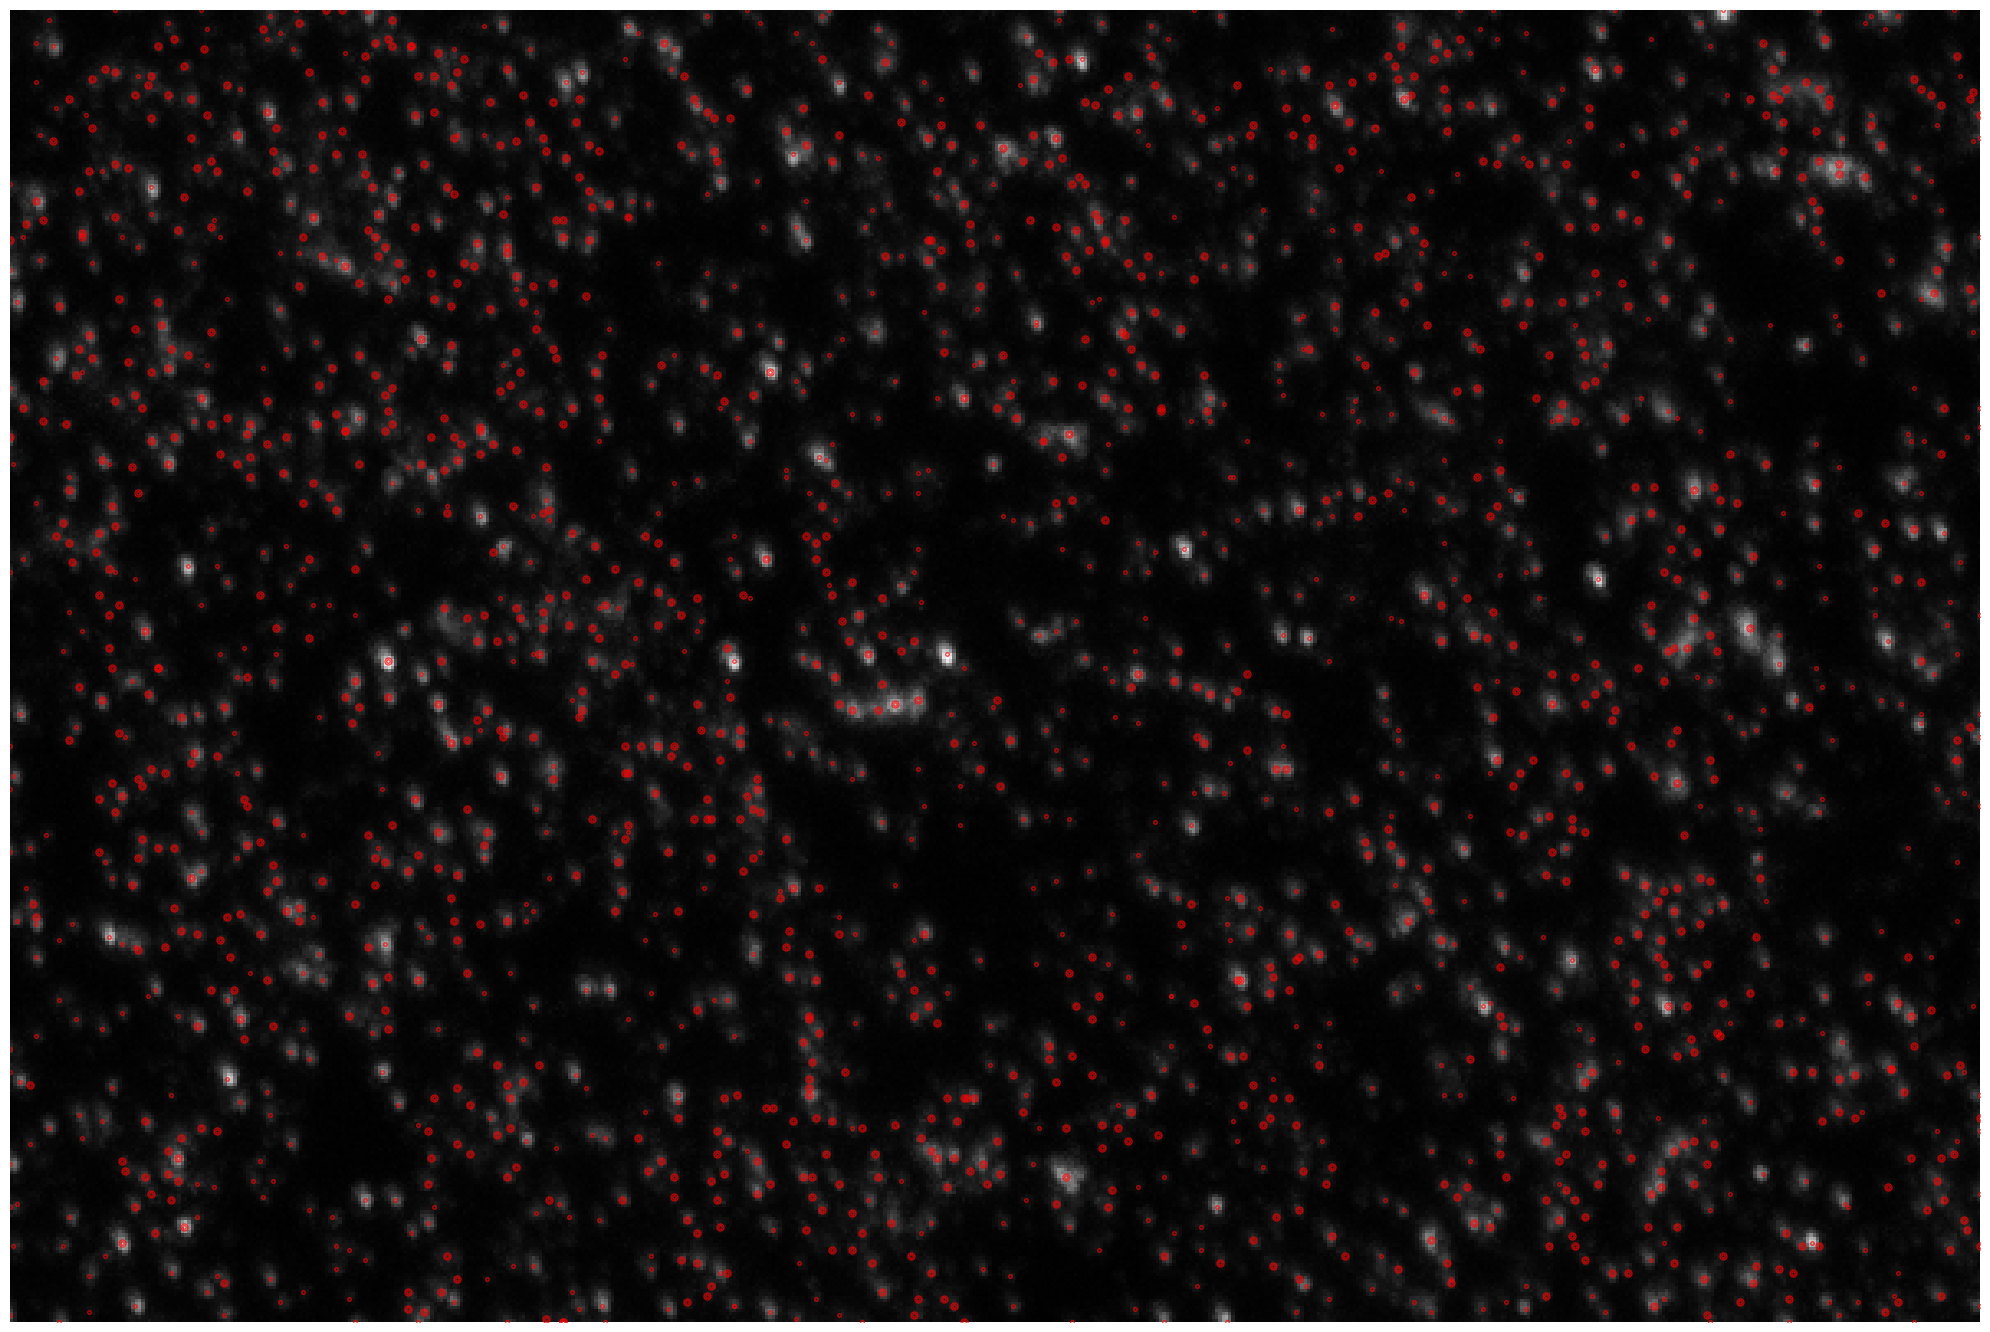

In [21]:
from prrt_clustering import compute_nearest_neighbor

clean = compute_nearest_neighbor(points, 2, 6)

fig = plt.figure(figsize=(20,20))
fig,axes = plot_data(tmp,split=True,fig=fig)
plot_points(points,ms=5,split=True,axes=axes)
plot_points(clean,ms=10,split=True,axes=axes)
# print(clean)
